# Figure 4: RT&T-MERFISH isoform usage in the mouse brain

From the published cell-by-isoform matrix to every panel of Fig. 4: isoform target, Saturn fit (seed 42), domain and
switch tables, the Sst state transition, and the figure.

**Conda envs:** `spatialmultivelo` (this kernel), `tutorial_lpc` (scVI), `stories` (CellRank 2).
**Time:** about 1 h on 8 CPU threads for the fit, plus SPLISOSM and the 500 permutations of the Sst step.

In [1]:
import sys; sys.path.insert(0, ".")
import nbutil as nb
nb.init("fig4")
DS = "rtt_merfish_s5_iso100_sv_pca_shrunk"; FIT = f"results/real_saturn/{DS}_norestart_lc0.3"
WS = "results/real_saturn/rtt_isoform_variants/whole_sv"
nb.mkdirs(WS)

ok      external_data/rtt_merfish/cellxgene_ISO_labels.h5ad  [RT&T-MERFISH cell-by-isoform matrix (see external_data README)]
ok      external_data/rtt_merfish/ensembl_tx2gene_mm.tsv  [Ensembl transcript to gene, mouse]


## 1. Isoform target
Section 5, 100 um bins. SPLISOSM selects genes with spatially variable isoform usage; the isoform target is a PCA of
their shrunken isoform ratios. The first step builds the unfiltered binomial target, which the second step only reports
as a comparison of the spatial ceiling.

The RNA GLM-PCA starts from an unseeded random state, so the published factors cannot be regenerated. The last step
puts them into the target (`steps/fig4_glmpc_published.npz`); everything else is rebuilt from the raw data.

In [2]:
nb.step("binomial_hv1000", "python scripts/rtt_isoform_binomial_glmpca.py --depthcov --hv 1000",
        ["results/real_saturn/targets_rtt_merfish_s5_iso100_binom_depthcov_hv1000.npz"])
nb.step("splisosm_multinomial", "python scripts/rtt_isoform_multinomial.py",
        [f"{WS}/sv_results.csv", "results/real_saturn/targets_rtt_merfish_s5_iso100_sv_multinom.npz"])
nb.step("isoform_ratio_pca", "python scripts/rtt_isoform_ratio_pca.py", [f"results/real_saturn/targets_{DS}.npz"])
STEPS = nb.Path(nb.__file__).resolve().parent / "steps"
nb.step("pin_glmpc", f"python {STEPS}/fig4_pin_glmpc.py {DS}", ["results/real_saturn/fig4_glmpc_pinned.txt"])

[skip] binomial_hv1000: outputs exist
[skip] splisosm_multinomial: outputs exist
[skip] isoform_ratio_pca: outputs exist
[run ] pin_glmpc: python /mnt/HDD2B/Users/yancui/saturn_repo/notebooks/steps/fig4_pin_glmpc.py rtt_merfish_s5_iso100_sv_pca_shrunk


[done] pin_glmpc: 0.0 min


## 2. Saturn fit
Seed 42 with no restarts and a higher cross-pathway cost (`lam_cross = 0.3`), so the isoform axis does not collapse onto
the RNA axis. Published settings: `SAT_THREADS=8`. Thread count changes the fit. The `--weights` run keeps the trained
model, which Fig. 7 needs.

In [3]:
nb.step("fit", f"python scripts/rtt_isoform_refit_nocollapse.py {DS} norestart_lc0.3", [f"{FIT}/axes.csv"], threads=8)
nb.step("fit_weights", f"python scripts/rtt_isoform_refit_nocollapse.py {DS} norestart_lc0.3 --weights", [f"{FIT}_weights/saturn_best.pt"], threads=8)
nb.compare_axes(f"{DS}_norestart_lc0.3")

[run ] fit: python scripts/rtt_isoform_refit_nocollapse.py rtt_merfish_s5_iso100_sv_pca_shrunk norestart_lc0.3


[done] fit: 1.0 min


[run ] fit_weights: python scripts/rtt_isoform_refit_nocollapse.py rtt_merfish_s5_iso100_sv_pca_shrunk norestart_lc0.3 --weights


[done] fit_weights: 0.9 min


                                            dataset      axis  max_abs_diff  abs_r
rtt_merfish_s5_iso100_sv_pca_shrunk_norestart_lc0.3     d_RNA           0.0    1.0
rtt_merfish_s5_iso100_sv_pca_shrunk_norestart_lc0.3 d_Isoform           0.0    1.0


,dataset,axis,max_abs_diff,abs_r
0,rtt_merfish_s5_iso100_sv_pca_shrunk_norestart_...,d_RNA,0.0,1.0
1,rtt_merfish_s5_iso100_sv_pca_shrunk_norestart_...,d_Isoform,0.0,1.0


## 3. Domains, usage along the isodepth and the boundary switch

In [4]:
nb.step("isodepth_tables", "python scripts/rtt_isoform_sv_isodepth.py", [f"{FIT}/isodepth/usage_screen.csv"])
nb.step("fig4_tables", "python scripts/rtt_isoform_sv_fig4_prep.py", [f"{FIT}/isodepth/domain_slopes.csv", f"{FIT}/isodepth/switch_23.csv"])
for t in ("domain_slopes.csv", "switch_23.csv"):
    nb.compare_table(f"{DS}_norestart_lc0.3/isodepth/{t}", tol=1e-4)

[run ] isodepth_tables: python scripts/rtt_isoform_sv_isodepth.py


[done] isodepth_tables: 25.0 min


[run ] fig4_tables: python scripts/rtt_isoform_sv_fig4_prep.py


[done] fig4_tables: 2.8 min


rtt_merfish_s5_iso100_sv_pca_shrunk_norestart_lc0.3/isodepth/domain_slopes.csv: shape (4674, 20) vs (4674, 20); max numeric diff 0; MATCH
rtt_merfish_s5_iso100_sv_pca_shrunk_norestart_lc0.3/isodepth/switch_23.csv: shape (1558, 28) vs (1558, 28); max numeric diff 0; MATCH


## 4. Sst state transition (panels k-n)
Sst interneurons on both sides of the boundary. scVI runs in `tutorial_lpc` and CellRank 2 in `stories`.

In [5]:
SST = "results/real_saturn/rtt_sst_transition"
nb.step("sst_prep", "python scripts/rtt_sst_isoform_transition.py prep", [f"{SST}/sst_cells.h5ad"])
nb.step("sst_scvi", "python scripts/rtt_sst_isoform_transition.py scvi", [f"{SST}/X_scvi.npy"], env="tutorial_lpc")
nb.step("sst_cellrank", "python scripts/rtt_sst_isoform_transition.py cellrank", [f"{SST}/cellrank_summary.json"], env="stories")
nb.step("sst_dynamics", "python scripts/rtt_sst_isoform_transition.py dynamics", [f"{SST}/isoform_dynamics.csv"])
nb.compare_table("rtt_sst_transition/isoform_dynamics.csv", tol=1e-4)

[run ] sst_prep: python scripts/rtt_sst_isoform_transition.py prep


[done] sst_prep: 0.1 min


[run ] sst_scvi: python scripts/rtt_sst_isoform_transition.py scvi


[done] sst_scvi: 0.1 min


[run ] sst_cellrank: python scripts/rtt_sst_isoform_transition.py cellrank


[done] sst_cellrank: 0.1 min


[run ] sst_dynamics: python scripts/rtt_sst_isoform_transition.py dynamics


[done] sst_dynamics: 0.2 min


rtt_sst_transition/isoform_dynamics.csv: shape (26, 25) vs (26, 25); max numeric diff 0; MATCH


{'file': 'rtt_sst_transition/isoform_dynamics.csv',
 'same_shape': True,
 'max_diff': 0.0}

## 5. Figure

[run ] figure: python /tmp/claude-1012/-mnt-HDD2B-Users-yancui/486f3289-97a4-41e8-a0a8-b5998a356a68/scratchpad/nbtest/fig4/Saturn/published_figures/fig4/fig4_parts.py


[done] figure: 0.3 min


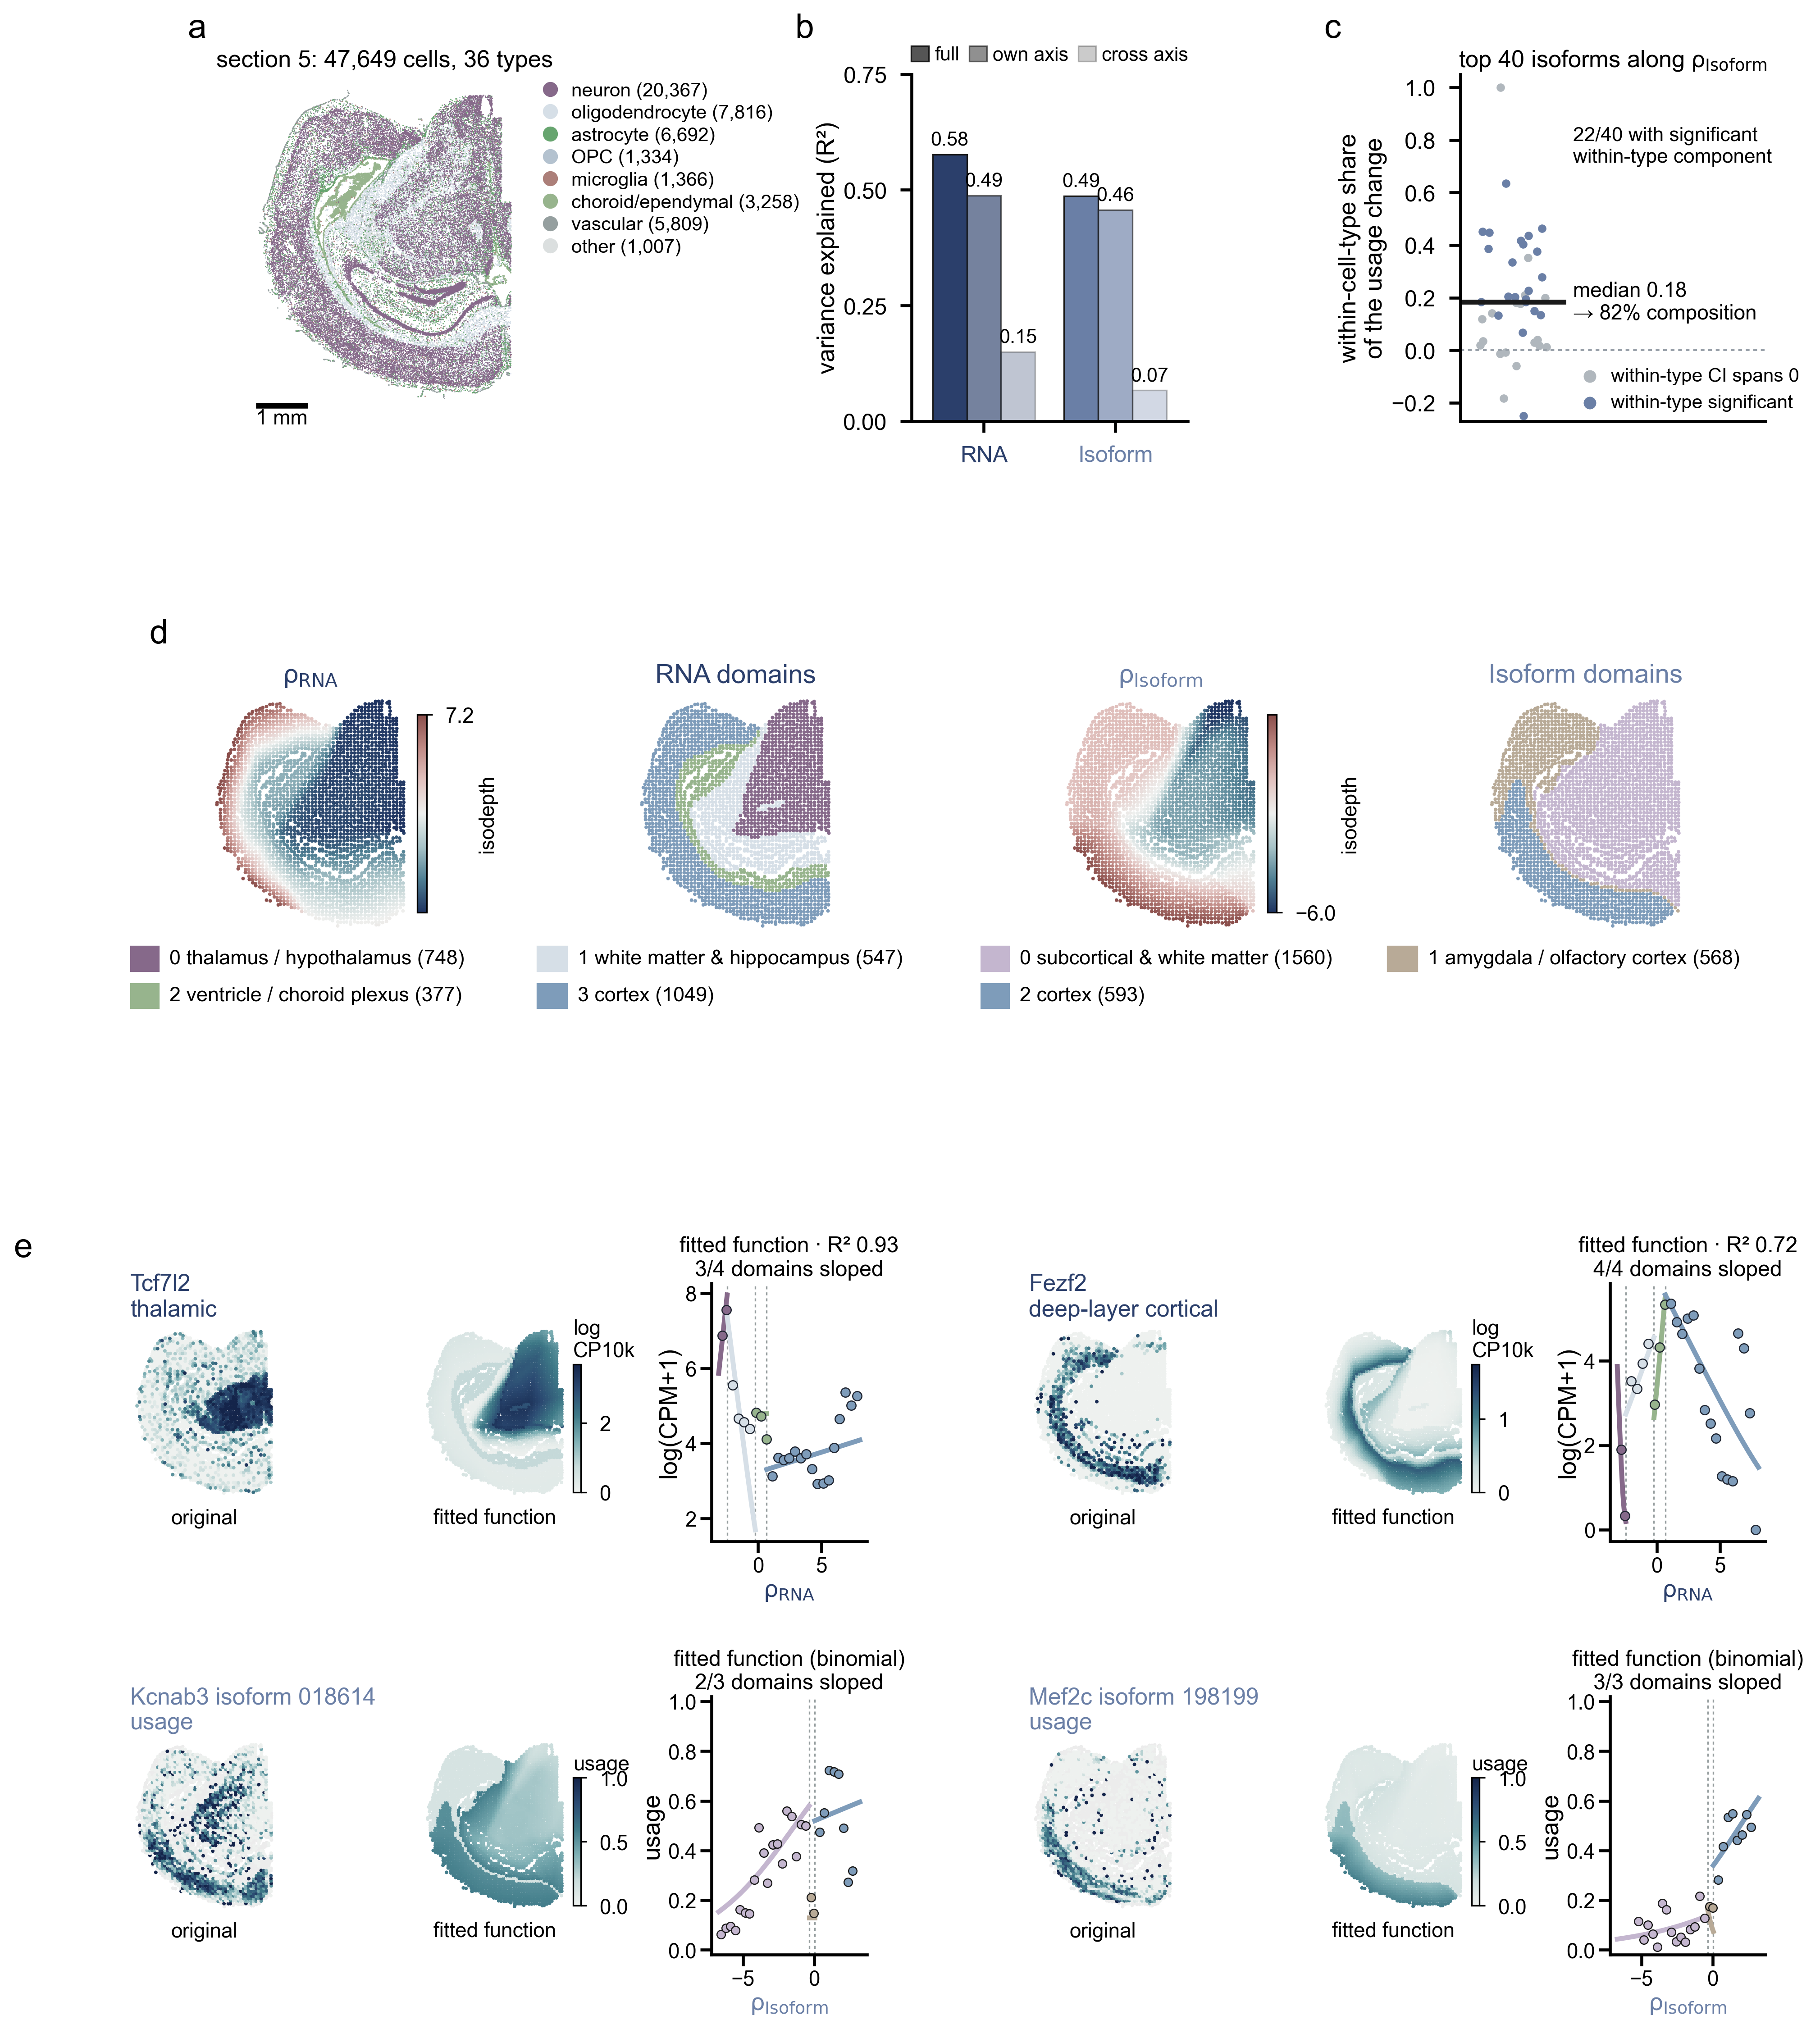

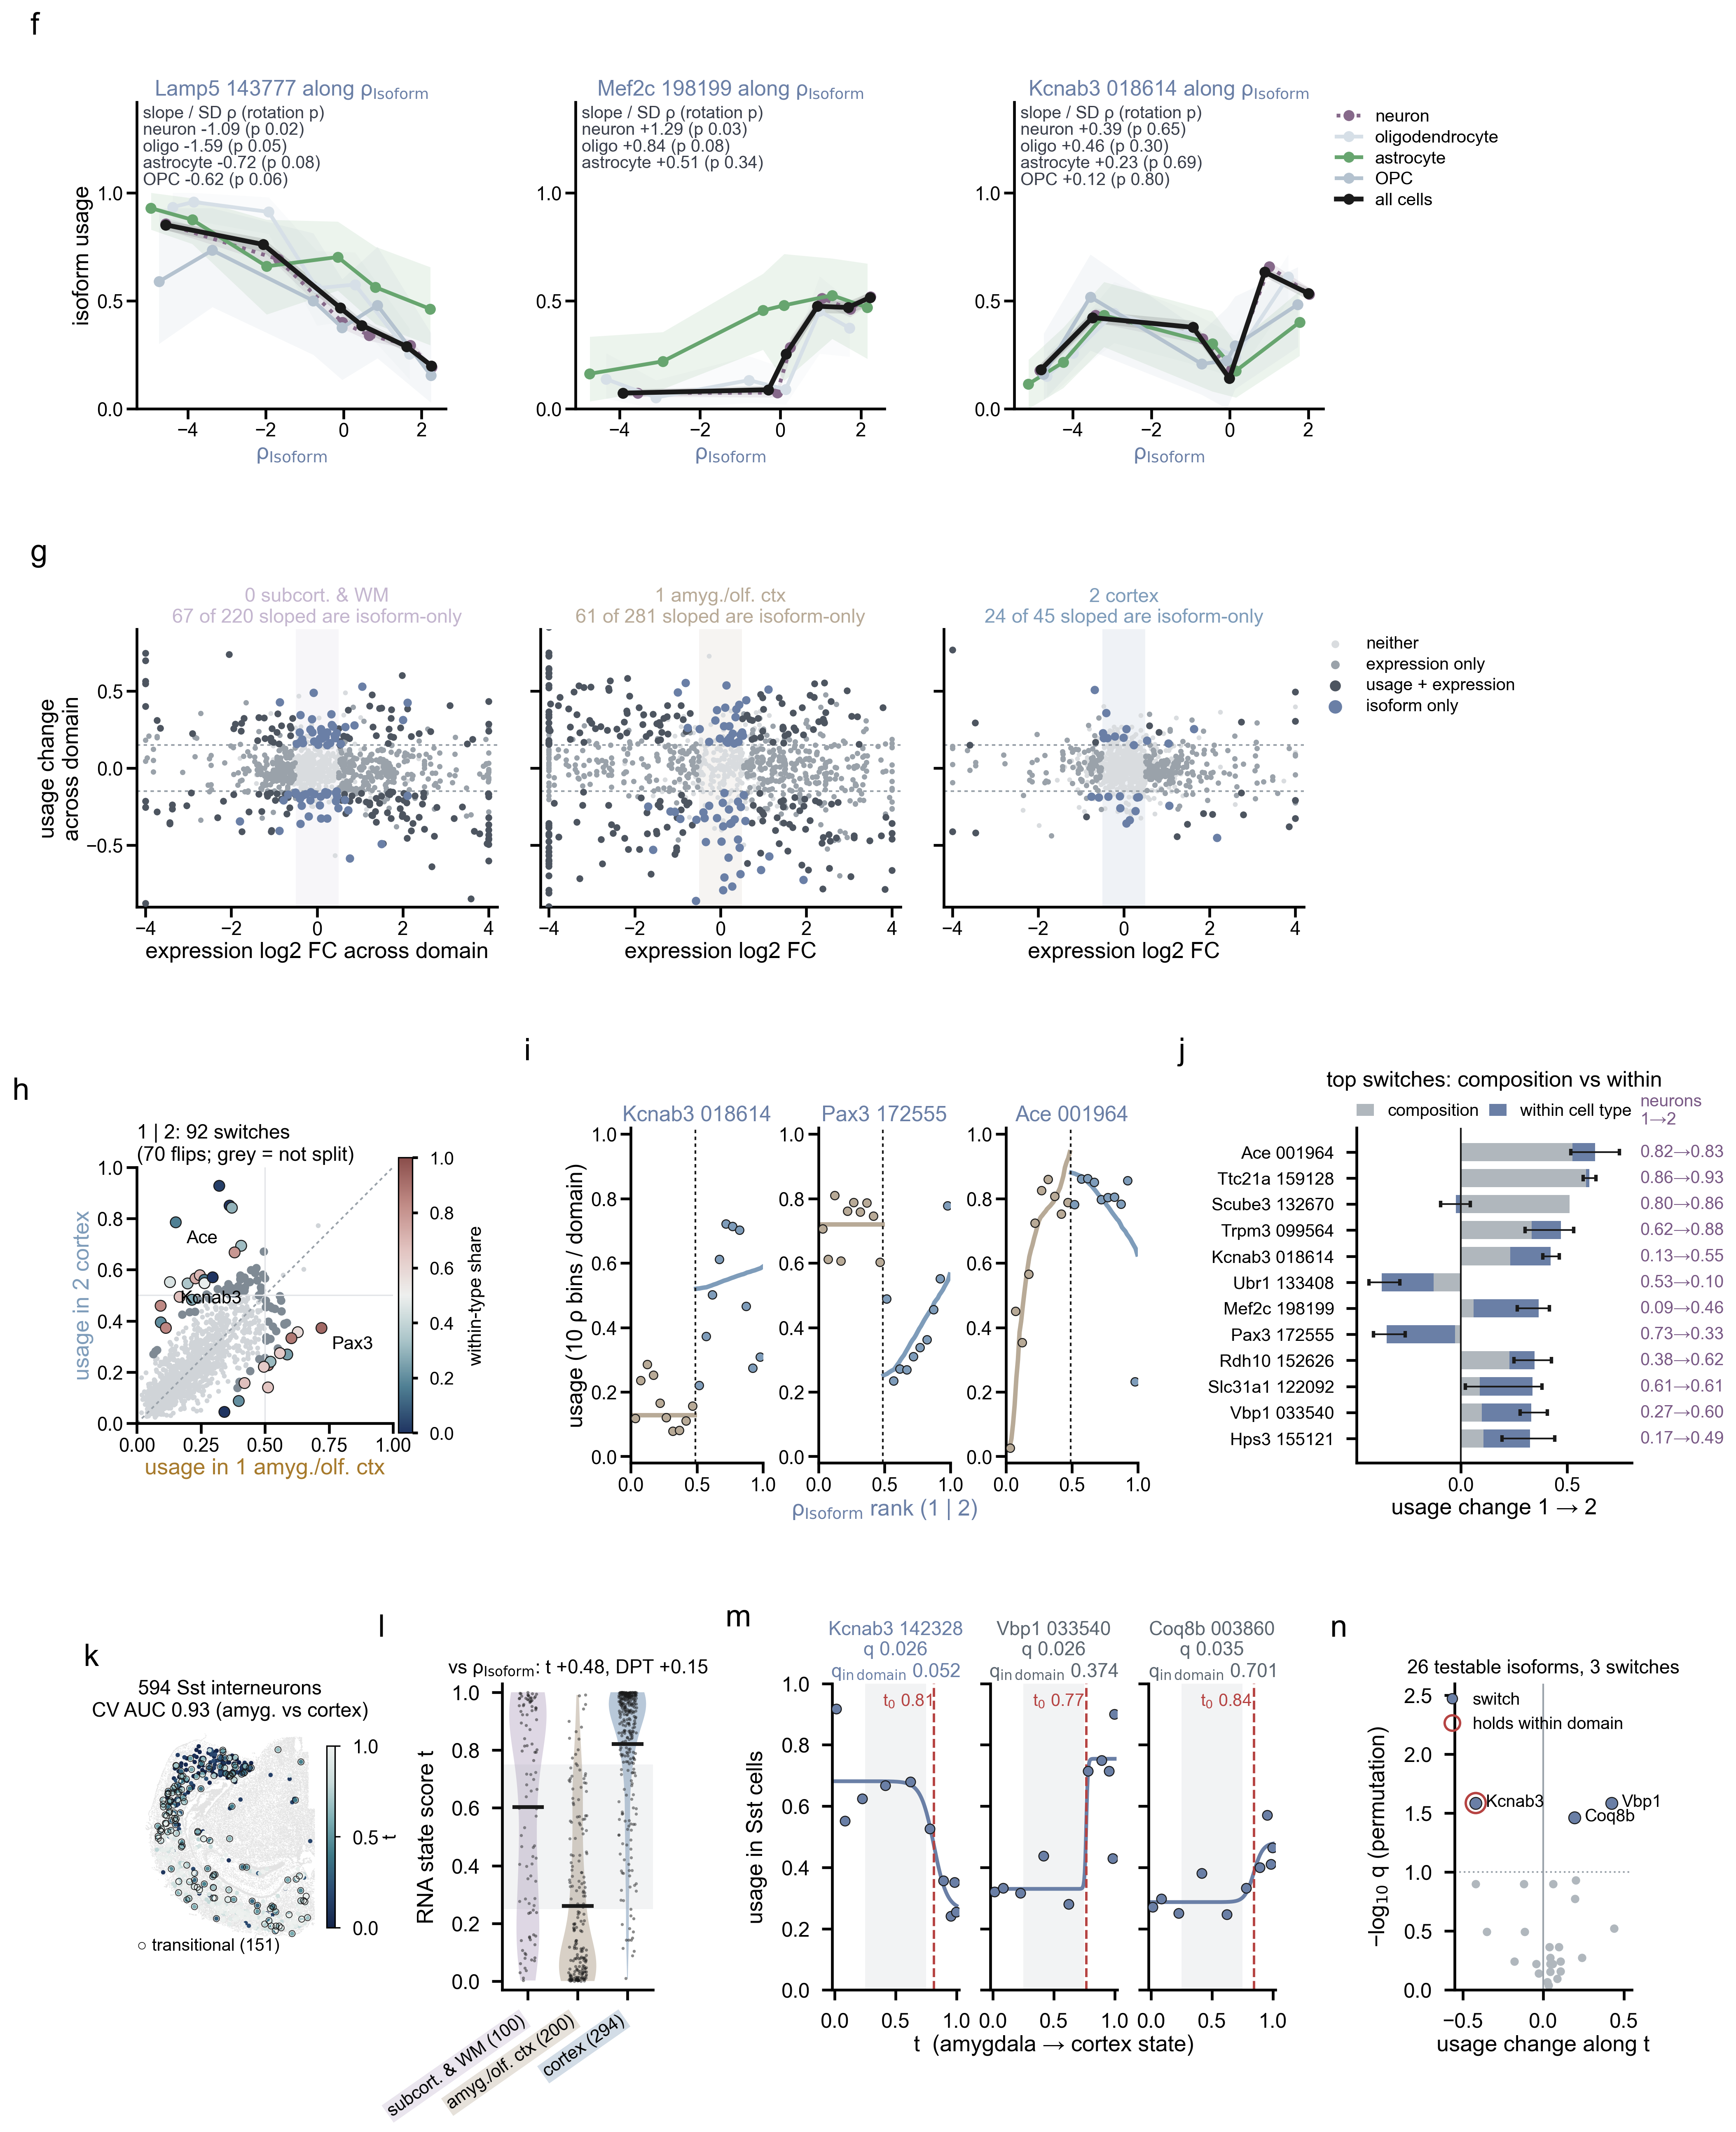

In [6]:
nb.step("figure", f"python {nb.PF}/fig4/fig4_parts.py")
nb.show("fig4/fig4_part1.png", "fig4/fig4_part2.png")